In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

# Carga del dataset Fashion-MNIST
(train_ds, test_ds), ds_info = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
    with_info=True
)

# Nombres de las 10 clases de prendas
class_names = [
    'Camiseta/Top', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo',
    'Sandalia', 'Camisa', 'Tenis', 'Bolso', 'Botín'
]

print(f"Clases totales: {ds_info.features['label'].num_classes}")
print(f"Ejemplos de entrenamiento: {ds_info.splits['train'].num_examples}")
print(f"Ejemplos de prueba: {ds_info.splits['test'].num_examples}")

c:\Users\rudol\OneDrive\Documentos\fashion_mnist_nn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Dl Completed...: 0 url [00:00, ? url/s]
Dl Completed...:  50%|█████     | 2/4 [00:01<00:01,  1.31 url/s]

Dl Completed...: 100%|██████████| 4/4 [00:03<00:00,  1.10 url/s]

Dl Completed...: 100%|██████████| 4/4 [00:03<00:00,  1.10 url/s]


Dataset fashion_mnist downloaded and prepared to C:\Users\rudol\tensorflow_datasets\fashion_mnist\3.0.1. Subsequent calls will reuse this data.



Clases totales: 10
Ejemplos de entrenamiento: 60000
Ejemplos de prueba: 10000


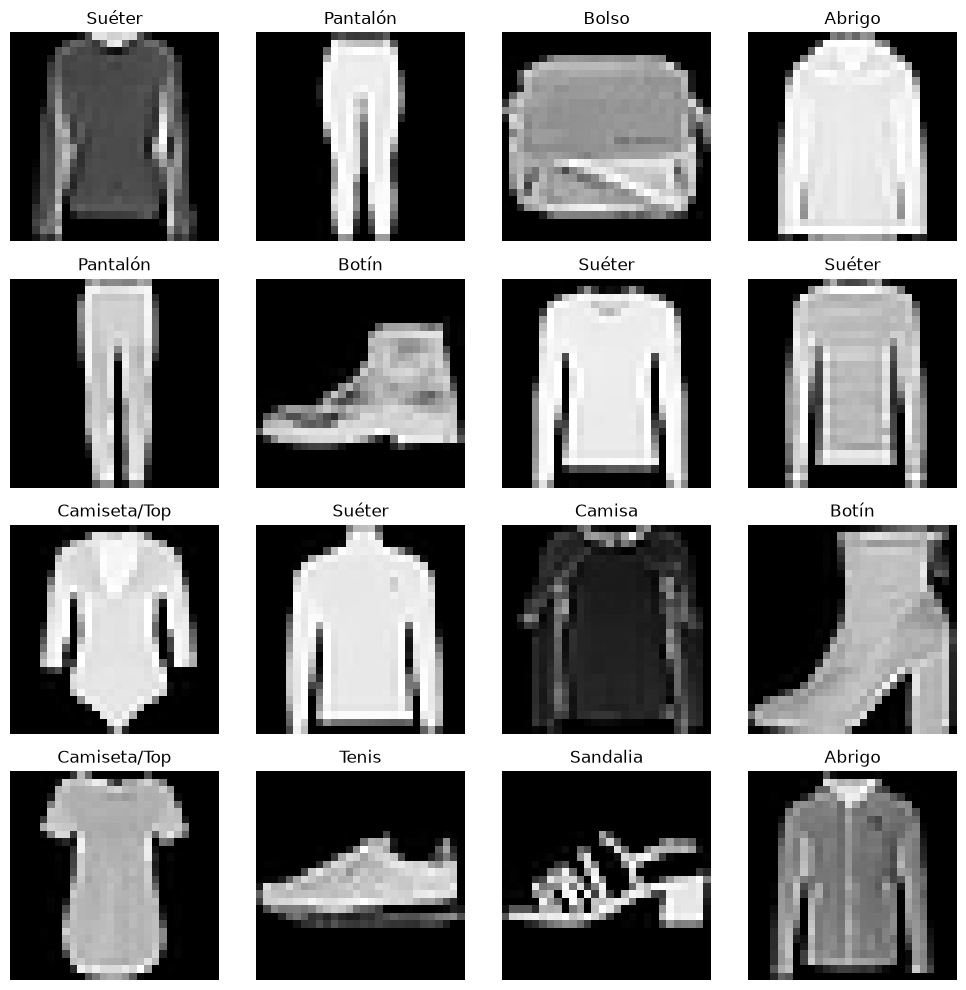

In [3]:
plt.figure(figsize=(10, 10))

# Tomamos el primer lote (batch) de 32 imágenes
for images, labels in train_ds.take(1):
    for i in range(16):
        ax = plt.subplot(4, 4, i + 1)
        # Convertimos el tensor de (28, 28, 1) a (28, 28) para graficar en 2D
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
def normalize_img(image, label):
    """Convierte imágenes de uint8 a float32 y normaliza entre 0 y 1."""
    return tf.cast(image, tf.float32) / 255.0, label

# Aplicamos la normalización y optimizamos el pipeline de datos
train_ds_norm = train_ds.map(normalize_img, num_parallel_calls=tf.data.AUTOTUNE)
train_ds_norm = train_ds_norm.cache().prefetch(tf.data.AUTOTUNE)

test_ds_norm = test_ds.map(normalize_img, num_parallel_calls=tf.data.AUTOTUNE)
test_ds_norm = test_ds_norm.cache().prefetch(tf.data.AUTOTUNE)

In [5]:
def build_and_train(model, name, epochs=10):
    print(f"\n--- Entrenando: {name} ---")
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    history = model.fit(
        train_ds_norm,
        validation_data=test_ds_norm,
        epochs=epochs,
        verbose=1
    )
    test_loss, test_acc = model.evaluate(test_ds_norm, verbose=0)
    print(f"Resultado Final {name} -> Test Accuracy: {test_acc:.4f}")
    return history, test_acc

# 1. Configuración 1: Arquitectura básica
model_1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# 2. Configuración 2: Dos capas ocultas
model_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# 3. Configuración 3: Mayor capacidad con Dropout
model_3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Entrenamos los 3 modelos
hist_1, acc_1 = build_and_train(model_1, "Configuración 1 (1 capa - 64)")
hist_2, acc_2 = build_and_train(model_2, "Configuración 2 (2 capas - 128/64)")
hist_3, acc_3 = build_and_train(model_3, "Configuración 3 (2 capas - 256/128 + Dropout)")


--- Entrenando: Configuración 1 (1 capa - 64) ---


Epoch 1/10


c:\Users\rudol\OneDrive\Documentos\fashion_mnist_nn\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8191 - loss: 0.5172 - val_accuracy: 0.8349 - val_loss: 0.4545
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8596 - loss: 0.3907 - val_accuracy: 0.8495 - val_loss: 0.4137
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8730 - loss: 0.3519 - val_accuracy: 0.8591 - val_loss: 0.3838
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8823 - loss: 0.3257 - val_accuracy: 0.8680 - val_loss: 0.3661
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8881 - loss: 0.3077 - val_accuracy: 0.8734 - val_loss: 0.3547
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8937 - loss: 0.2921 - val_accuracy: 0.8761 - val_loss: 0.3480
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8978 - loss: 0.2791 - val_accuracy: 0.8761 - val_loss: 0.3486
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9019 - loss: 0.2682 - val_accurac

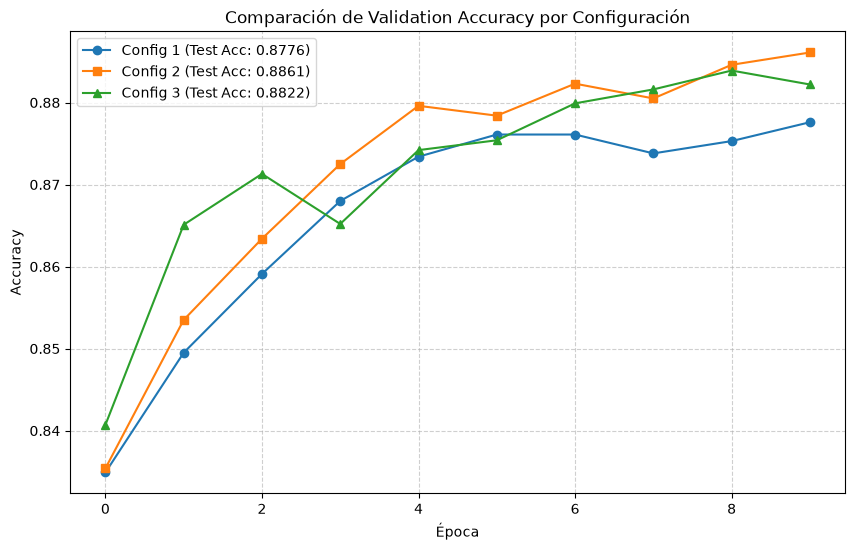

In [6]:
plt.figure(figsize=(10, 6))

plt.plot(hist_1.history['val_accuracy'], label=f'Config 1 (Test Acc: {acc_1:.4f})', marker='o')
plt.plot(hist_2.history['val_accuracy'], label=f'Config 2 (Test Acc: {acc_2:.4f})', marker='s')
plt.plot(hist_3.history['val_accuracy'], label=f'Config 3 (Test Acc: {acc_3:.4f})', marker='^')

plt.title('Comparación de Validation Accuracy por Configuración')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


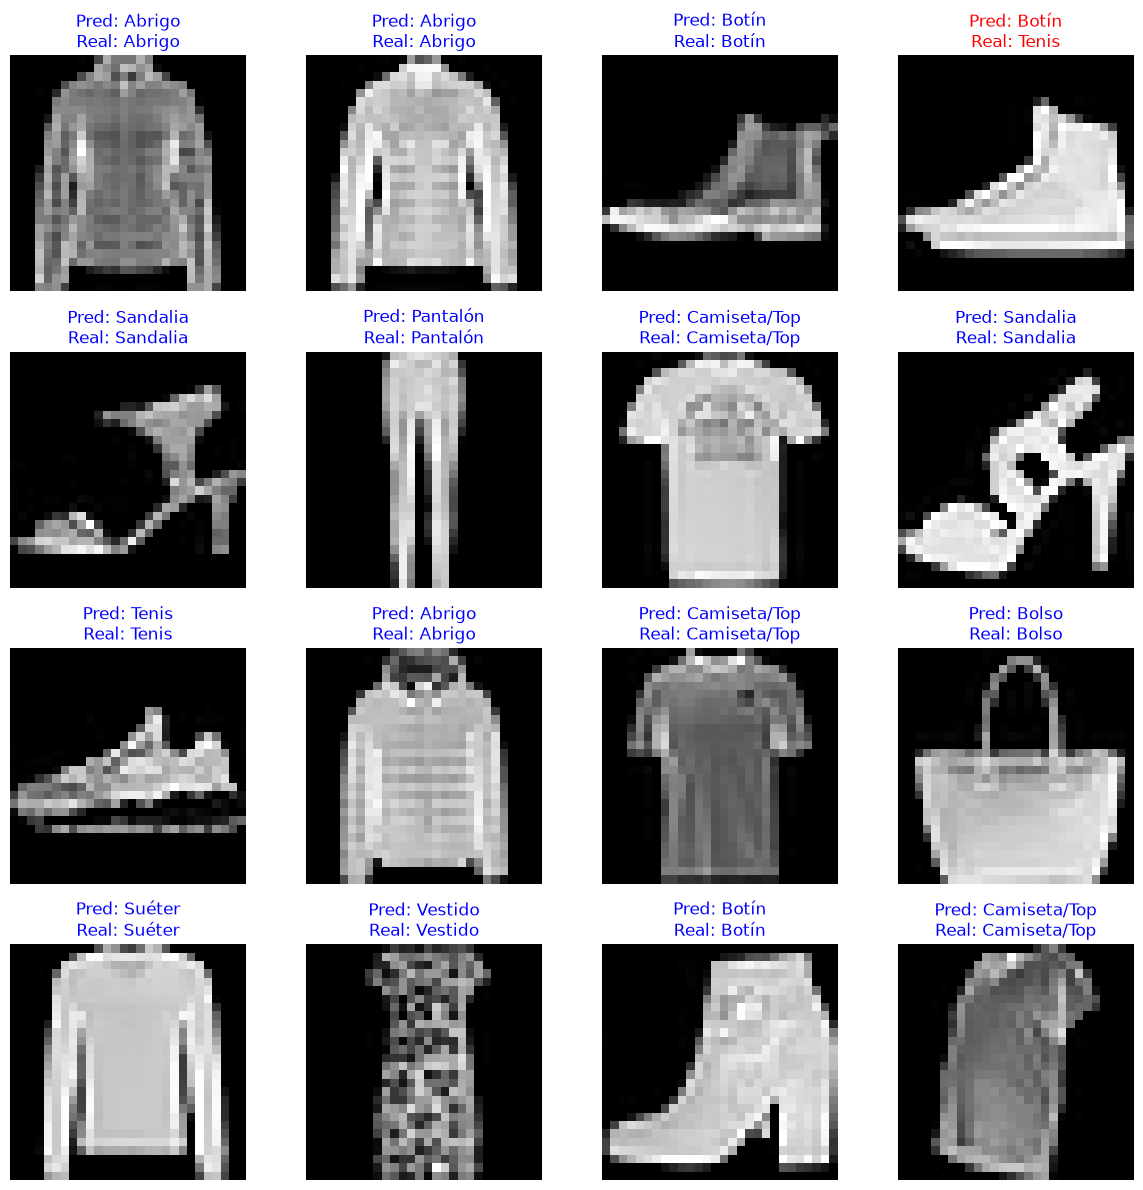

In [7]:
plt.figure(figsize=(12, 12))

for images, labels in test_ds_norm.take(1):
    predictions = model_3.predict(images)
    for i in range(16):
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        
        pred_label = np.argmax(predictions[i])
        true_label = labels[i].numpy()
        
        color = 'blue' if pred_label == true_label else 'red'
        plt.title(f"Pred: {class_names[pred_label]}\nReal: {class_names[true_label]}", color=color)
        plt.axis("off")

plt.tight_layout()
plt.show()